In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import VotingClassifier, RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize
import warnings

warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_csv("ECGCvdata.csv")

<h2 style="color:#8F9F87; font-weight:700;">Exploratory Data Analysis (EDA) </h2>

In [ ]:
df.shape

(1200, 56)

In [ ]:
df.head()

,RECORD,hbpermin,Pseg,PQseg,QRSseg,QRseg,QTseg,RSseg,STseg,Tseg,...,RMSSD,QRSarea,QRSperi,PQslope,QRslope,RSslope,STslope,NN50,pNN50,ECG_signal
0,1,74.925669,0.076508,0.108889,0.088254,0.043571,0.193016,0.044683,0.104762,0.130476,...,292.296636,18.457618,63.615239,-0.014364,0.075270,-0.070846,0.012606,2,5.882353,ARR
1,2,68.503469,0.072483,0.096181,0.093924,0.046267,0.193490,0.047656,0.099566,0.089149,...,318.563915,23.043230,67.787773,-0.021207,0.083773,-0.077458,0.016175,1,3.225806,ARR
2,3,83.488603,0.071154,0.086610,0.039530,0.018590,0.132479,0.020940,0.092949,0.094444,...,273.165412,10.756353,29.253827,-0.042542,NaN,NaN,0.027131,16,42.105263,ARR
3,4,68.503469,0.082812,0.108160,0.090365,0.045226,0.188802,0.045139,0.098437,0.088281,...,313.046941,23.845086,65.228737,-0.017806,0.091591,-0.088559,0.017022,2,6.451613,ARR
4,5,82.080000,0.070760,0.102632,0.101023,0.049415,0.193713,0.051608,0.092690,0.085965,...,263.225676,20.942791,72.830353,-0.016650,0.064547,-0.062246,0.016191,2,5.405405,ARR


In [ ]:
df.describe()

,RECORD,hbpermin,Pseg,PQseg,QRSseg,QRseg,QTseg,RSseg,STseg,Tseg,...,SDSD,RMSSD,QRSarea,QRSperi,PQslope,QRslope,RSslope,STslope,NN50,pNN50
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,...,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,432.000000,431.000000,1200.000000,1200.000000,1200.000000
mean,600.500000,81.893980,0.060902,0.078099,0.048238,0.024437,0.141541,0.023800,0.093303,0.102714,...,42.484060,199.417894,7.675047,23.915846,-0.071647,0.141737,-0.150496,0.041659,6.442500,8.112425
std,346.554469,19.324351,0.009453,0.019897,0.034649,0.017501,0.029225,0.017175,0.013332,0.022594,...,105.722123,112.292014,8.452832,25.070324,0.049705,0.073086,0.077532,0.026456,7.748445,10.325033
min,1.000000,12.857143,0.021556,0.044526,0.000000,0.000000,0.098761,0.000000,0.052338,0.034936,...,0.800624,61.711281,0.000000,0.000000,-0.219938,0.028660,-0.315525,0.008183,0.000000,0.000000
25%,300.750000,67.563000,0.053943,0.060344,0.015101,0.007804,0.116016,0.007143,0.089423,0.090046,...,4.060951,123.147741,0.000000,0.124186,-0.106660,0.082613,-0.240304,0.023853,1.000000,0.613497
50%,600.500000,79.872000,0.060642,0.075184,0.044692,0.022676,0.137019,0.021965,0.097825,0.099210,...,11.265829,183.603851,5.228299,19.904060,-0.058518,0.108418,-0.116241,0.034460,3.000000,3.680982
75%,900.250000,96.000000,0.066849,0.095190,0.083032,0.041915,0.166314,0.041097,0.101200,0.112408,...,44.785825,248.101035,14.355389,46.194325,-0.027685,0.229659,-0.087565,0.049778,10.000000,12.883436
max,1200.000000,160.500000,0.095317,0.145577,0.120160,0.065278,0.211111,0.058333,0.138444,0.198413,...,1725.927603,1478.488460,33.131007,86.577082,-0.005427,0.270786,-0.027983,0.164633,37.000000,52.727273


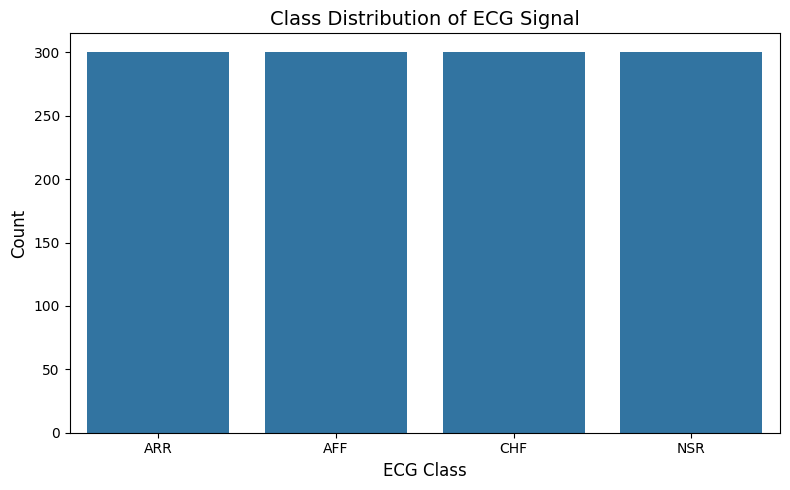

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(x="ECG_signal", data=df).grid(False)

plt.title("Class Distribution of ECG Signal", fontsize=14)
plt.xlabel("ECG Class", fontsize=12)
plt.ylabel("Count", fontsize=12)

plt.tight_layout()
plt.show()

<h3 style="color:#8F9F87; font-weight:700;">Missing Values Analysis </h3>

In [ ]:
df= df.replace(0, np.nan)

In [ ]:
missing = df.isnull().sum()[df.isnull().sum() > 0]
print(f"Total missing values in dataset: {missing}")
print(f"Total duplicate rows in dataset: {df.duplicated().sum()}")

Total missing values in dataset: QRSseg        49
QRseg         49
RSseg         72
QRtoQSdur    769
RStoQSdur    769
QRdis        229
QSdis        220
RSdis        326
PonPQang     557
PQRang       768
QRSang       769
RSTang       769
STToffang    426
QRSarea      338
QRSperi      220
QRslope      768
RSslope      769
NN50         293
pNN50        293
dtype: int64
Total duplicate rows in dataset: 0


<Axes: >

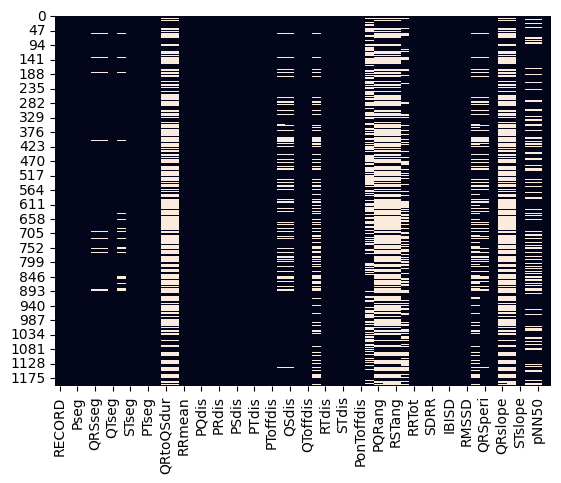

In [ ]:
sns.heatmap(df.isnull(), cbar=False)

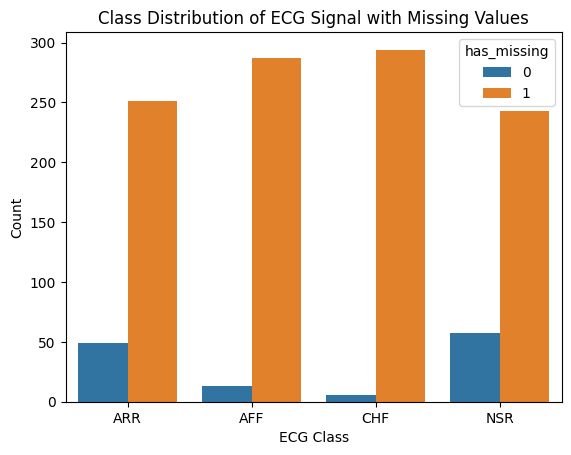

In [ ]:
df['has_missing'] = df.isnull().any(axis=1).astype(int)

sns.countplot(x='ECG_signal', hue='has_missing', data=df).grid(False)
plt.title("Class Distribution of ECG Signal with Missing Values")
plt.xlabel("ECG Class")
plt.ylabel("Count")
plt.show()

In [ ]:
df['has_missing'] = df.isnull().any(axis=1)

missing_distribution = pd.crosstab(
    df['has_missing'],
    df['ECG_signal'],
    margins=True,
    normalize='columns'  # Show percentage within each class
) * 100

print("\nPercentage of records with missing values by ECG signal type:")
print(missing_distribution.round(2))


Percentage of records with missing values by ECG signal type:
ECG_signal     AFF    ARR   CHF   NSR    All
has_missing                                 
False         4.33  16.33   2.0  19.0  10.42
True         95.67  83.67  98.0  81.0  89.58


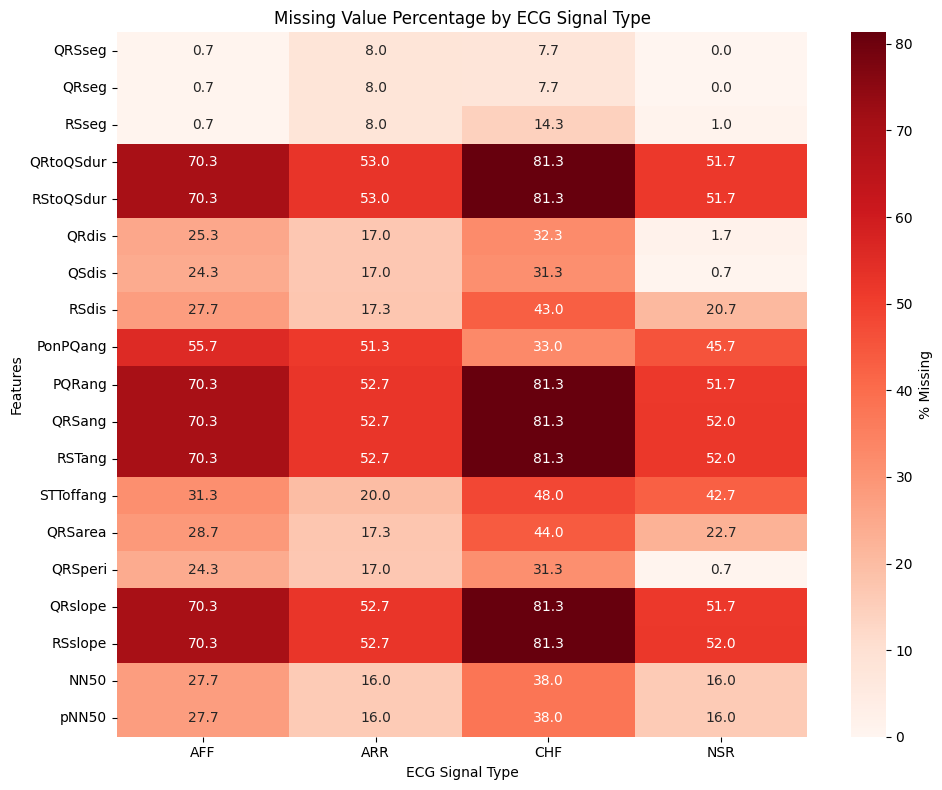

In [ ]:
missing_by_type = df.groupby('ECG_signal').apply(
    lambda x: (x.isnull().sum() / len(x) * 100)
).T

# Only show features with some missing values
missing_by_type = missing_by_type[missing_by_type.sum(axis=1) > 0]

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(missing_by_type, annot=True, fmt='.1f', cmap='Reds', cbar_kws={'label': '% Missing'})
plt.title('Missing Value Percentage by ECG Signal Type')
plt.xlabel('ECG Signal Type')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

<p style="color:#8F9F87; font-weight:700;">This analysis indicates that the missingness mechanism is not missing completely at random (MCAR) since higher proportions of missing values were observed in abnormal ECG classes (CHF and AFF) in comparison to the rest.  To account for this, missing values higher than 50% were dropped. For values with a low missing percentage, KNN imputation was applied. <p>


In [ ]:
X = df.drop(columns=['ECG_signal'])
y = df['ECG_signal']

In [ ]:
high_missing = X.columns[X.isnull().mean() > 0.5]
df = df.drop(columns=['RECORD'])
# KEEP QRSang
high_missing = high_missing.drop('QRSang', errors='ignore')

X = X.drop(columns=high_missing)

In [ ]:
X_with_indicators = X.copy()

for col in X.columns:
    if X[col].isnull().sum() > 0:
        X_with_indicators[col + '_missing'] = X[col].isnull().astype(int)

<h3 style="color:#8F9F87; font-weight:700;">Univariate Analysis </h3>

In [ ]:
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
target = 'ECG_signal'

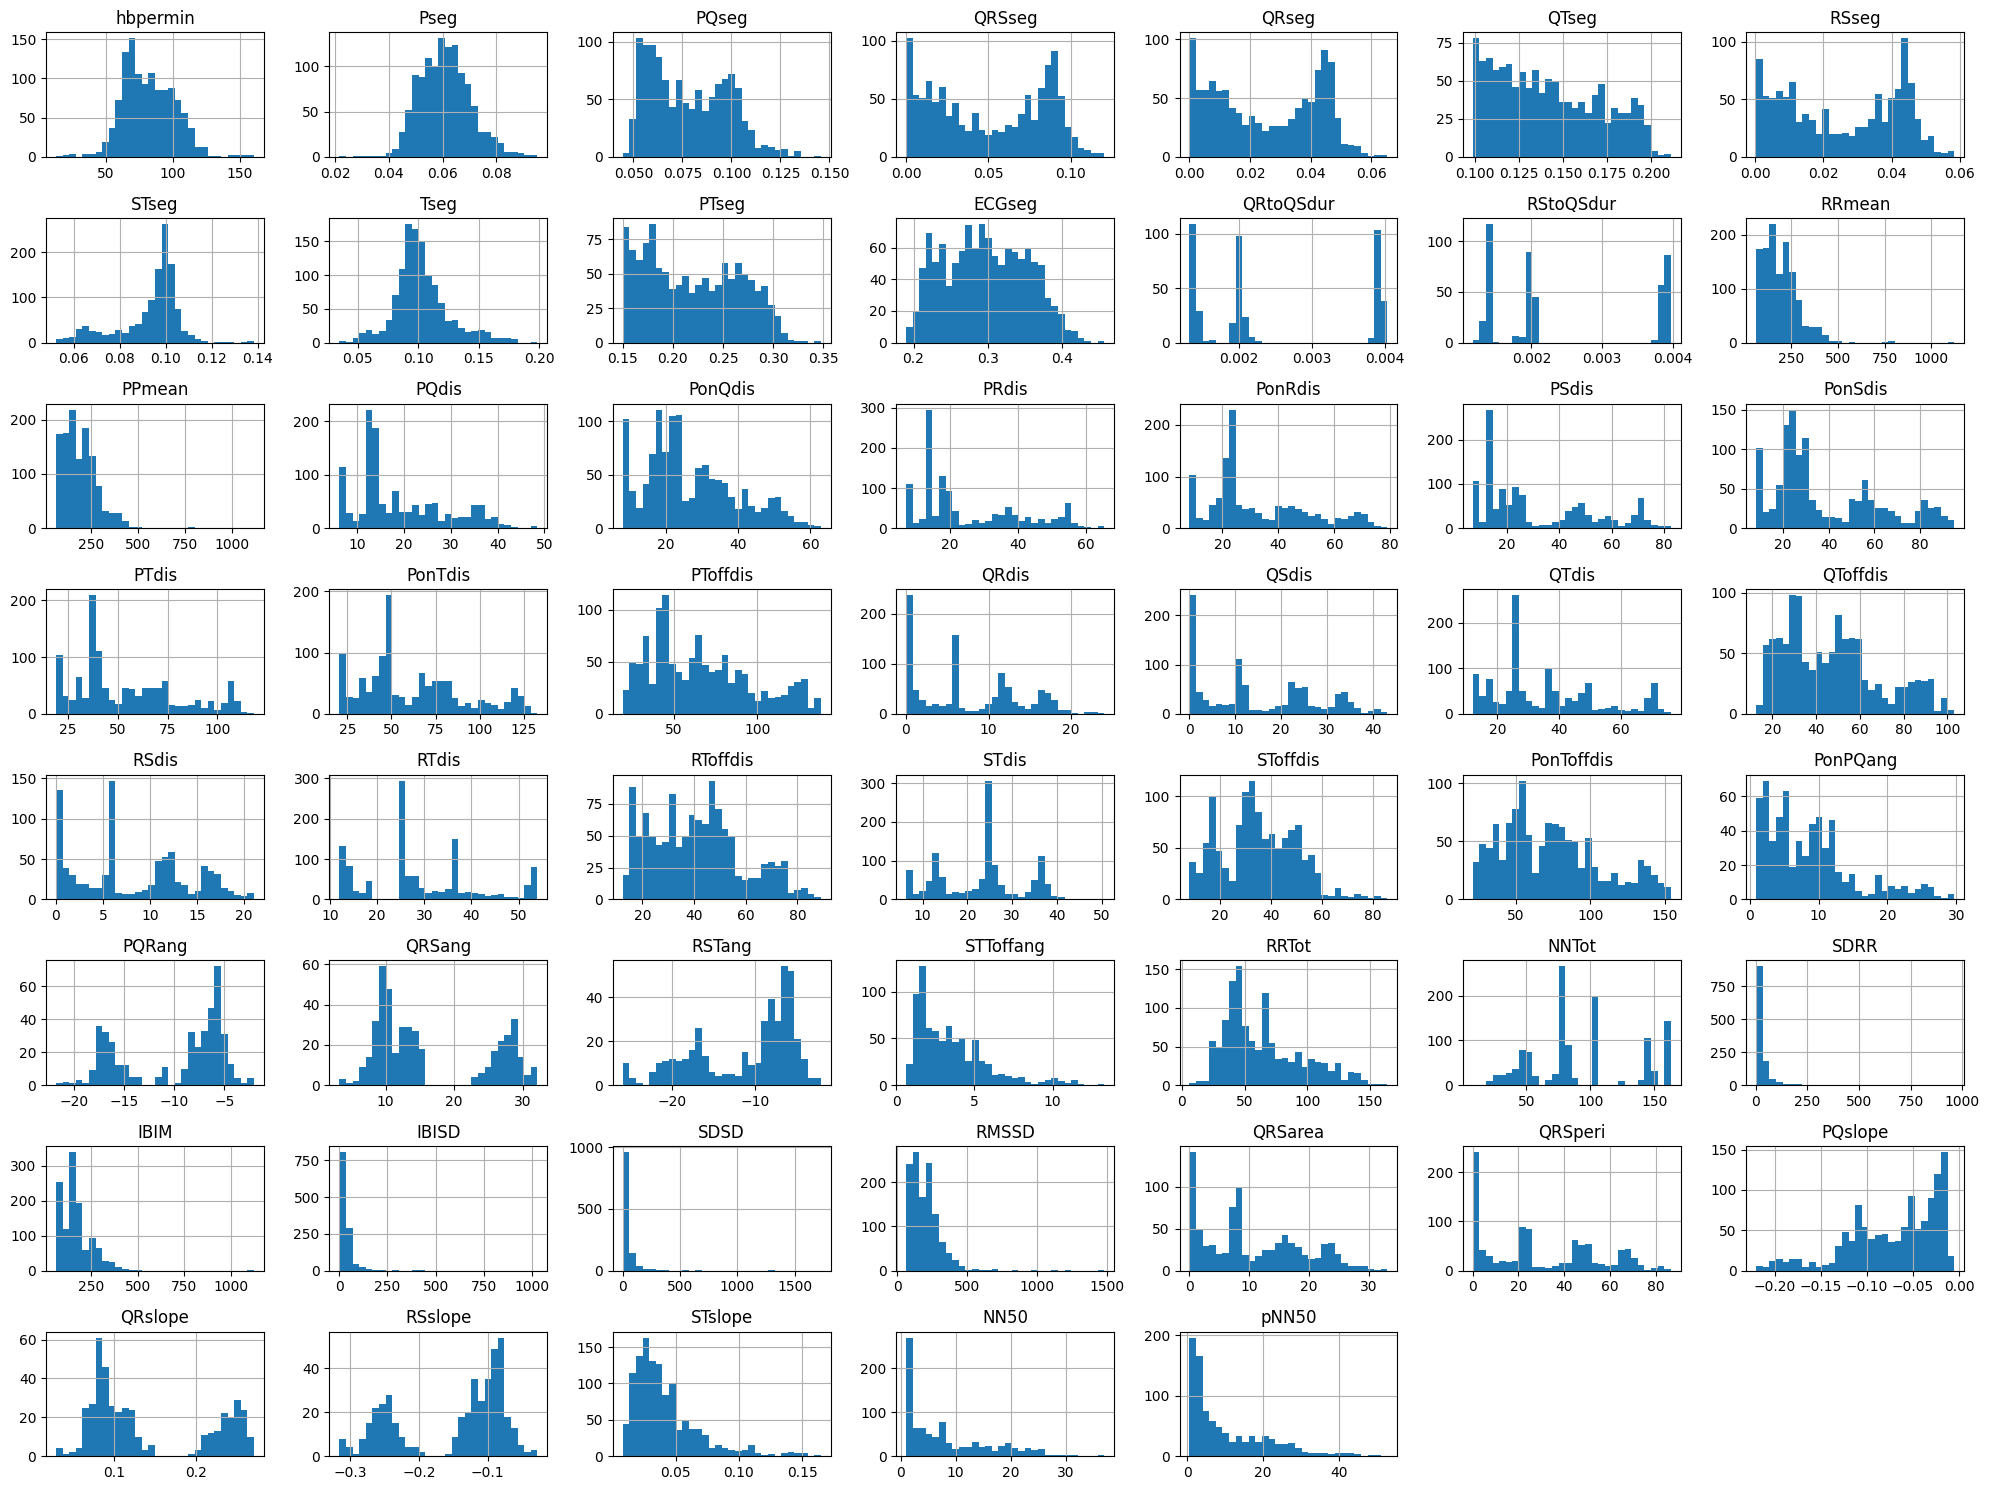

In [ ]:
df[num_cols].hist(figsize=(20, 15), bins=30)
plt.tight_layout()

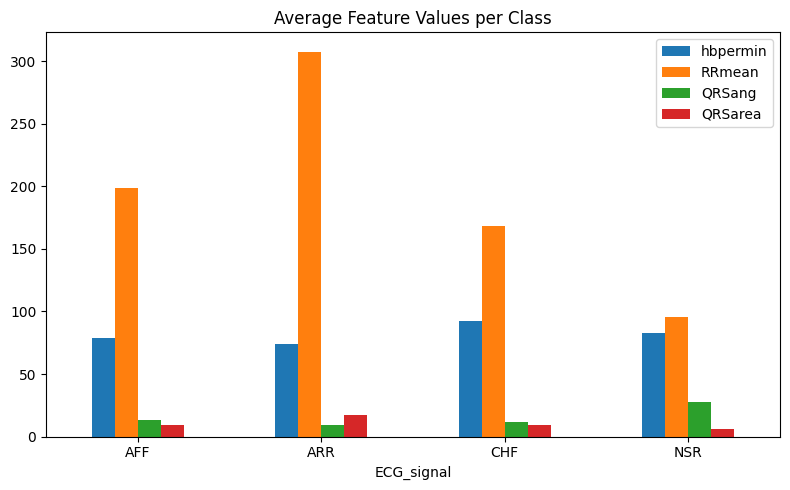

In [ ]:
df.groupby('ECG_signal')[['hbpermin', 'RRmean', 'QRSang', 'QRSarea']].mean().plot(
    kind='bar',
    figsize=(8,5)
)
plt.title("Average Feature Values per Class")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

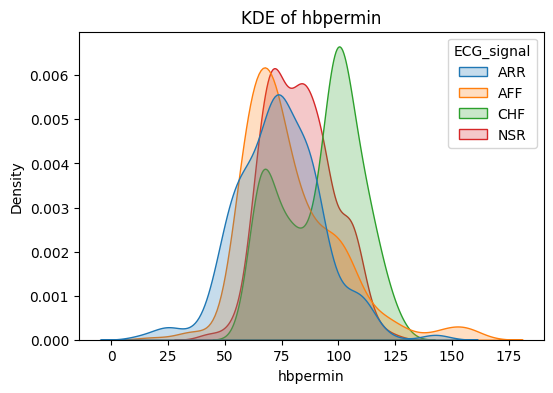

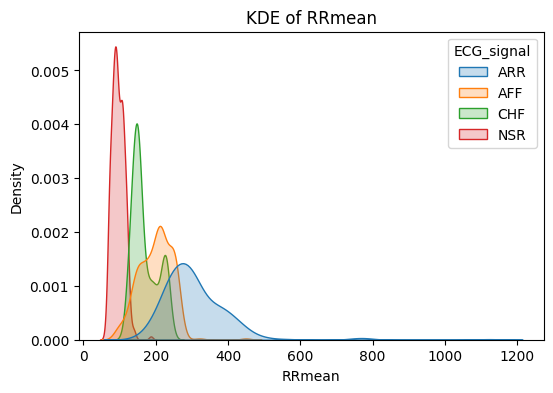

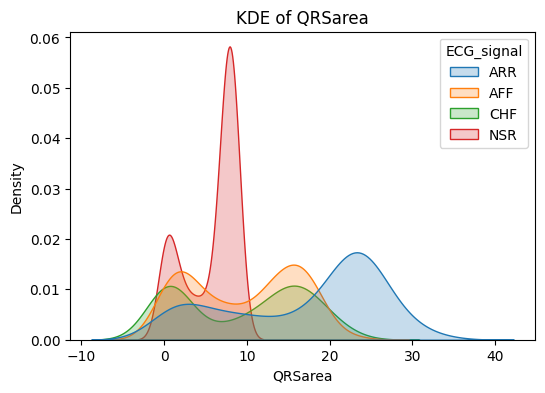

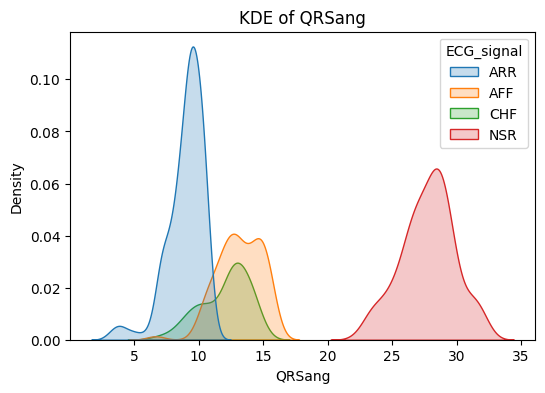

In [ ]:
for col in ['hbpermin', 'RRmean', 'QRSarea', 'QRSang']:
    plt.figure(figsize=(6,4))
    sns.kdeplot(data=df, x=col, hue=target, fill=True)
    plt.title(f'KDE of {col}')
    plt.show()

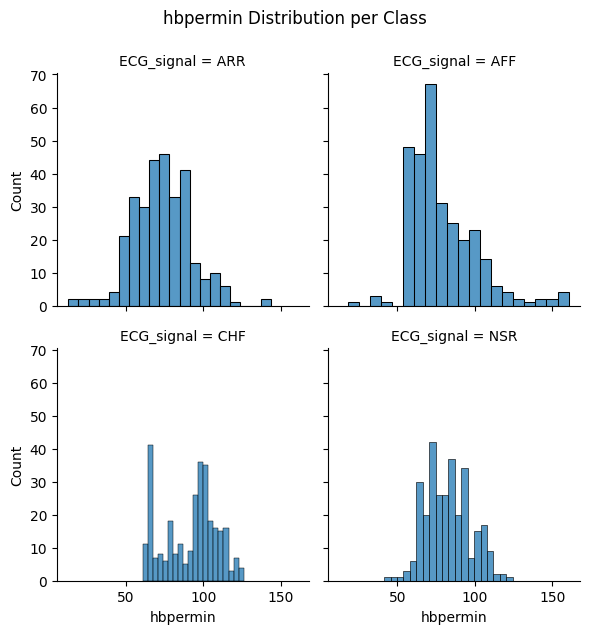

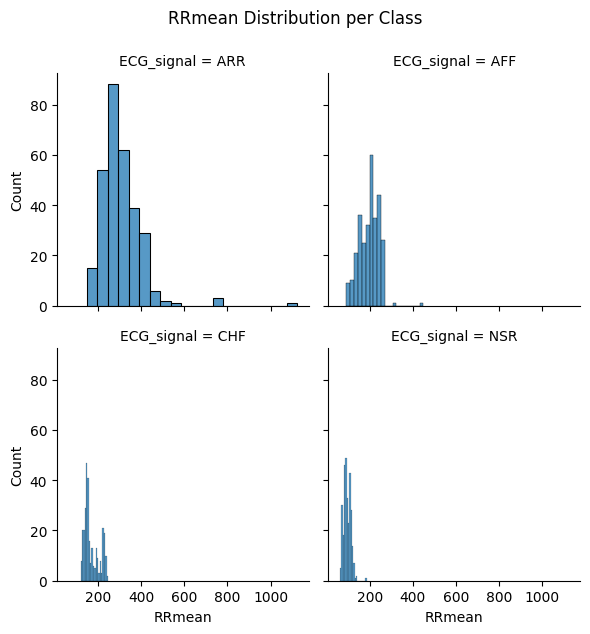

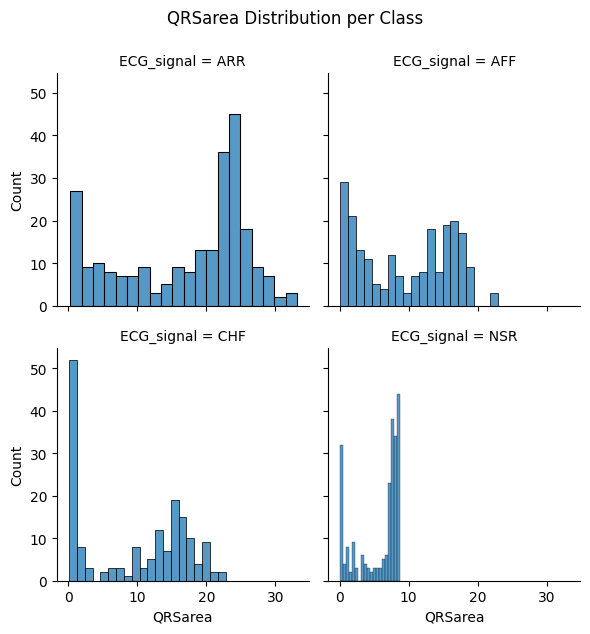

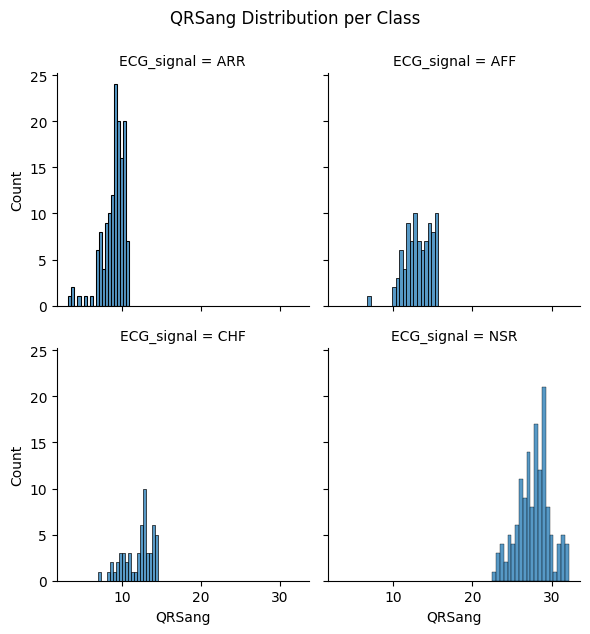

In [ ]:
plt.show()
for feature in ['hbpermin', 'RRmean', 'QRSarea', 'QRSang']:
    g = sns.FacetGrid(df, col=target, col_wrap=2)
    g.map(sns.histplot, feature, bins=20)
    g.fig.suptitle(f"{feature} Distribution per Class", y=1.05)
    plt.show()

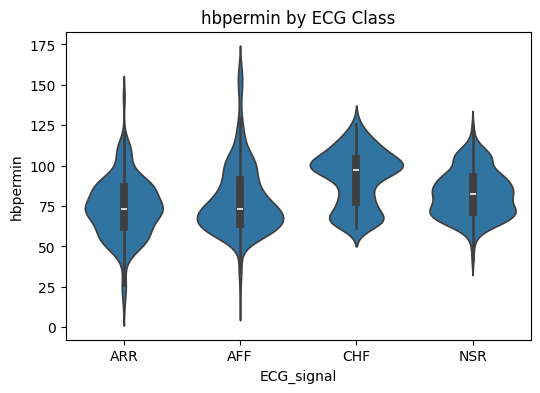

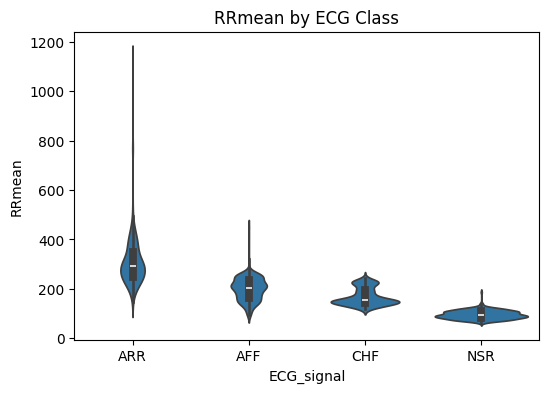

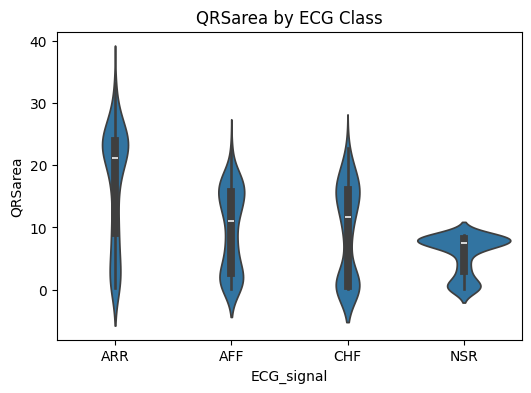

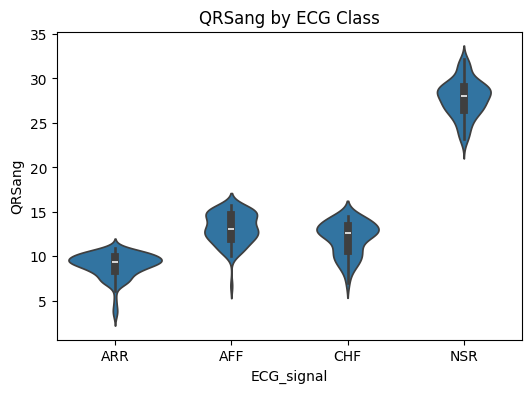

In [ ]:
for col in ['hbpermin', 'RRmean', 'QRSarea', 'QRSang']:
    plt.figure(figsize=(6,4))
    sns.violinplot(x=target, y=col, data=df)
    plt.title(f'{col} by ECG Class')
    plt.show()

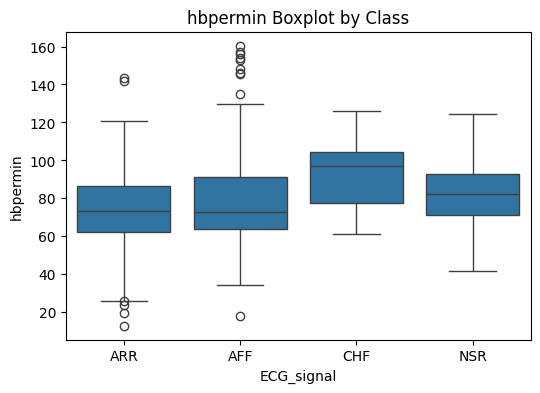

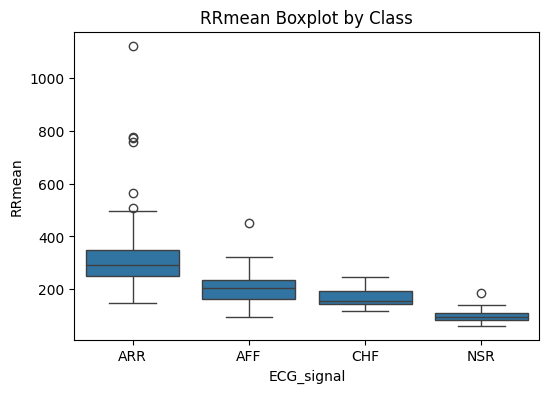

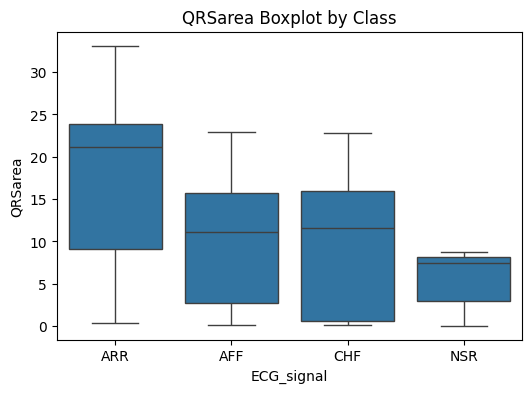

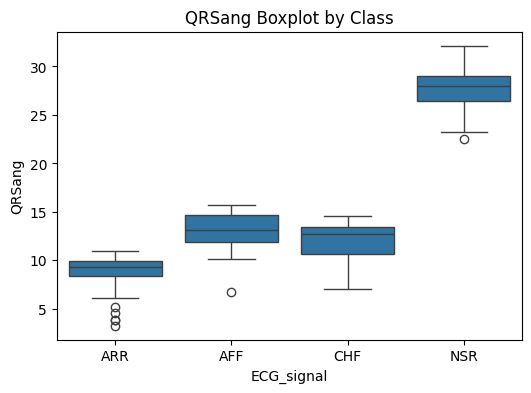

In [ ]:
for col in ['hbpermin', 'RRmean', 'QRSarea', 'QRSang']:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=target, y=col, data=df)
    plt.title(f'{col} Boxplot by Class')
    plt.show()

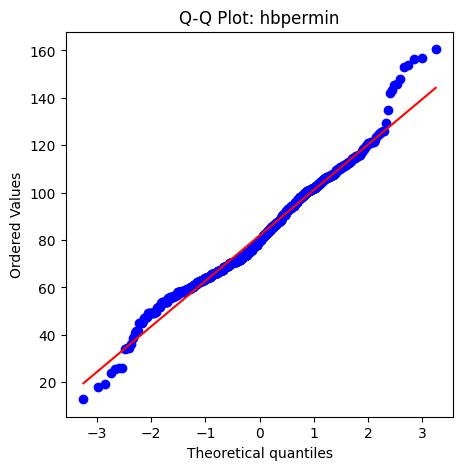

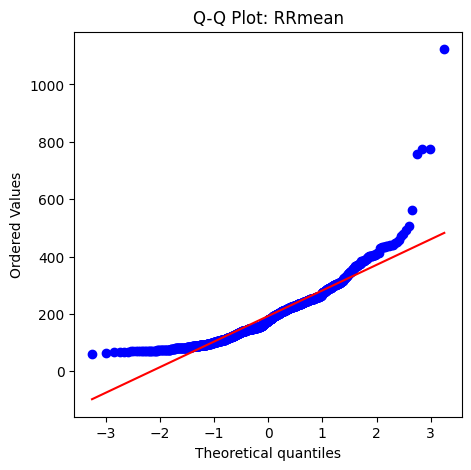

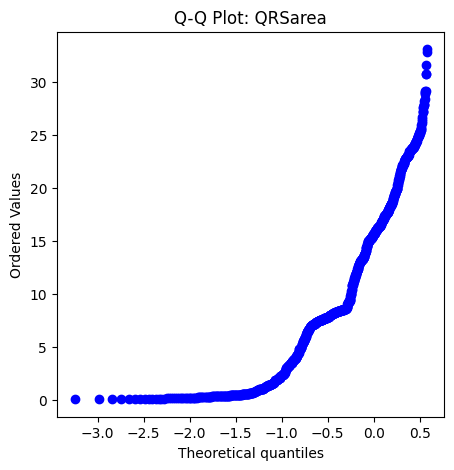

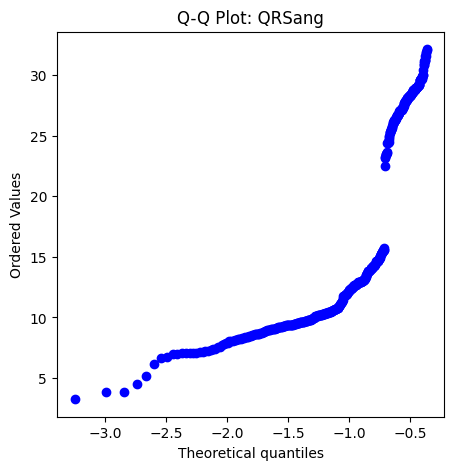

In [ ]:
for col in ['hbpermin', 'RRmean', 'QRSarea', 'QRSang']:
    plt.figure(figsize=(5,5))
    stats.probplot(df[col], dist="norm", plot=plt)
    plt.title(f'Q-Q Plot: {col}')
    plt.show()

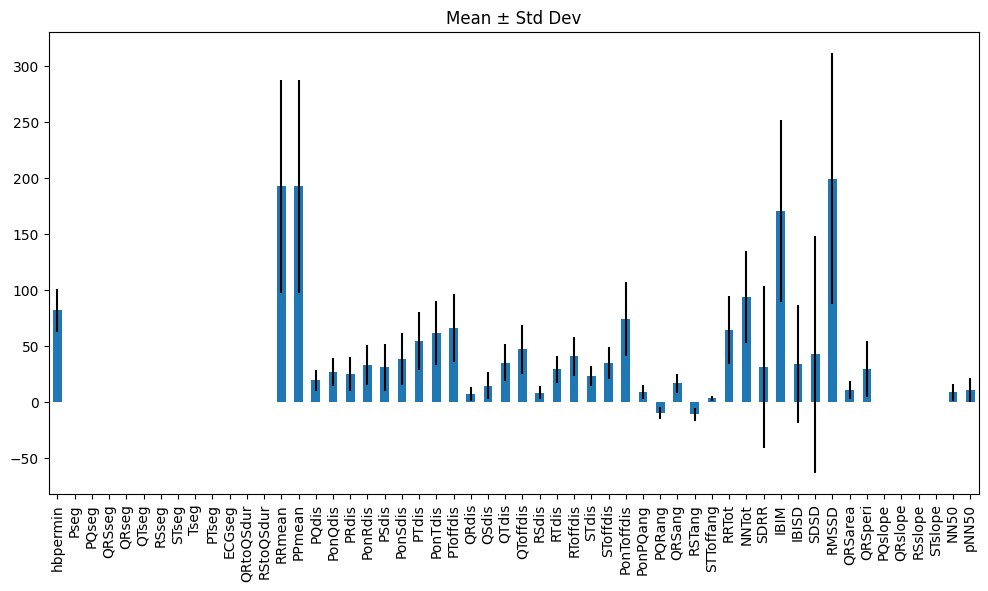

In [ ]:
means = df[num_cols].mean()
stds = df[num_cols].std()

plt.figure(figsize=(12,6))
means.plot(kind='bar', yerr=stds)
plt.title("Mean ± Std Dev")
plt.show()

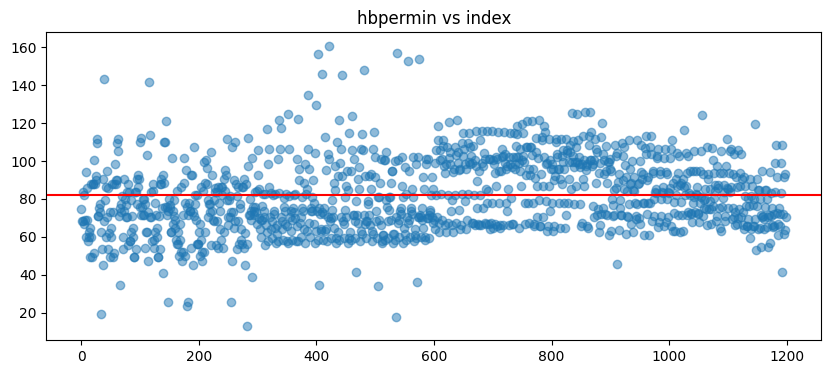

In [ ]:
plt.figure(figsize=(10,4))
plt.scatter(df.index, df['hbpermin'], alpha=0.5)
plt.axhline(df['hbpermin'].mean(), color='red')
plt.title("hbpermin vs index")
plt.show()

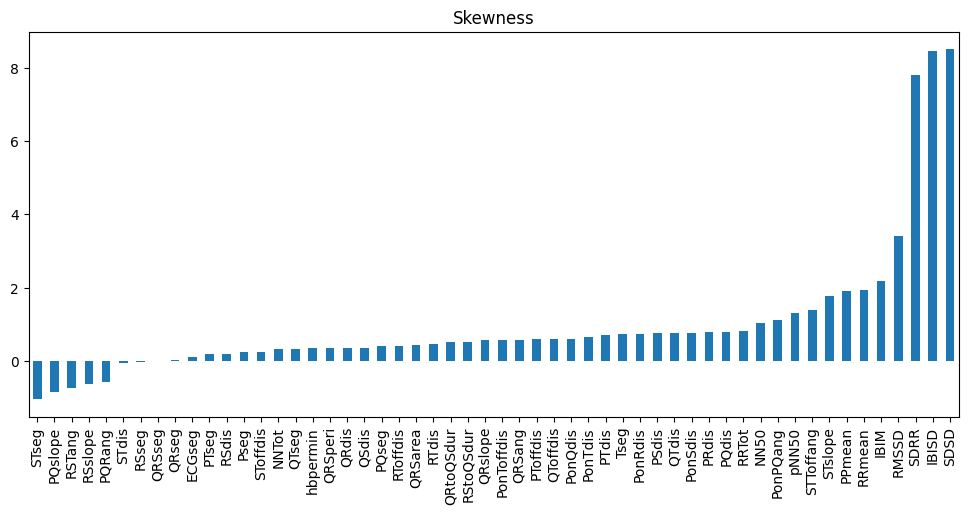

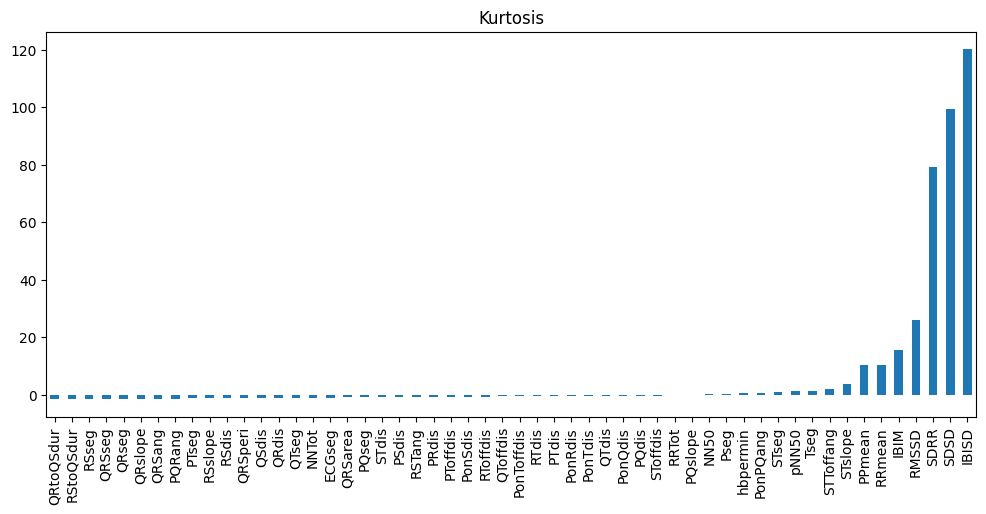

In [ ]:
skew = df[num_cols].skew()
kurt = df[num_cols].kurtosis()

skew.sort_values().plot(kind='bar', figsize=(12,5), title="Skewness")
plt.show()

kurt.sort_values().plot(kind='bar', figsize=(12,5), title="Kurtosis")
plt.show()

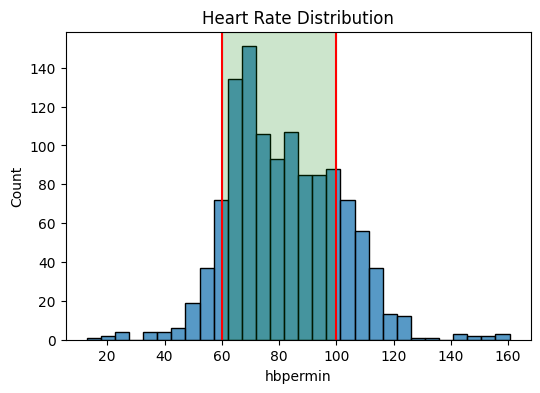

In [ ]:
plt.figure(figsize=(6,4))
sns.histplot(df['hbpermin'], bins=30)

#60 - 100 is the normal range for heartbeat.

plt.axvspan(60, 100, color='green', alpha=0.2)
plt.axvline(60, color='red')
plt.axvline(100, color='red')

plt.title("Heart Rate Distribution")
plt.show()

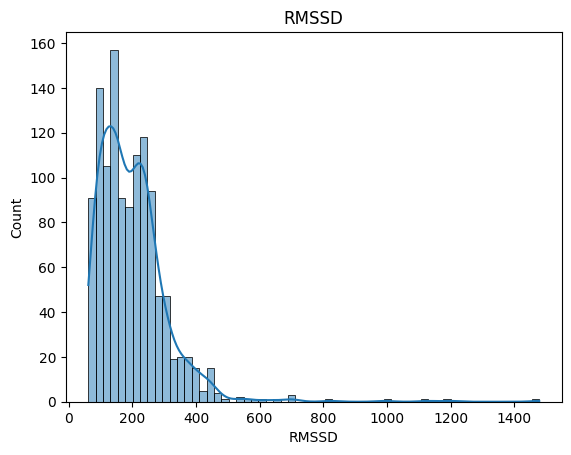

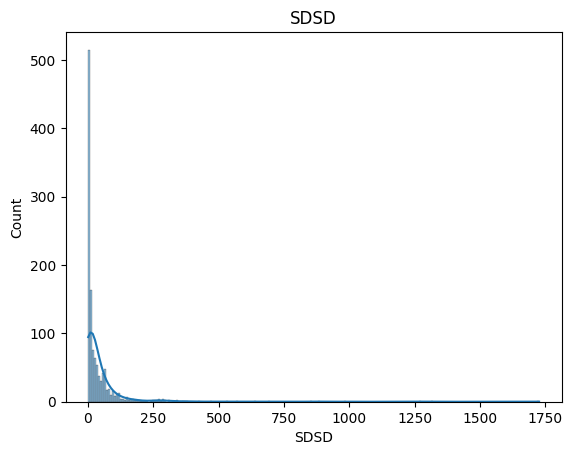

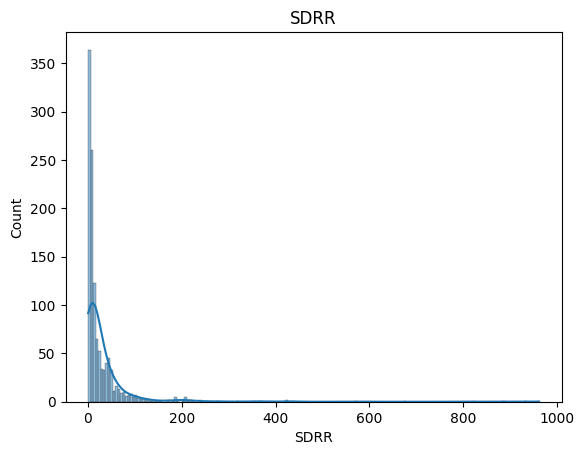

In [ ]:
hrv_features = ['RMSSD', 'SDSD', 'SDRR']

for col in hrv_features:
    sns.histplot(df[col], kde=True)
    plt.title(col)
    plt.show()

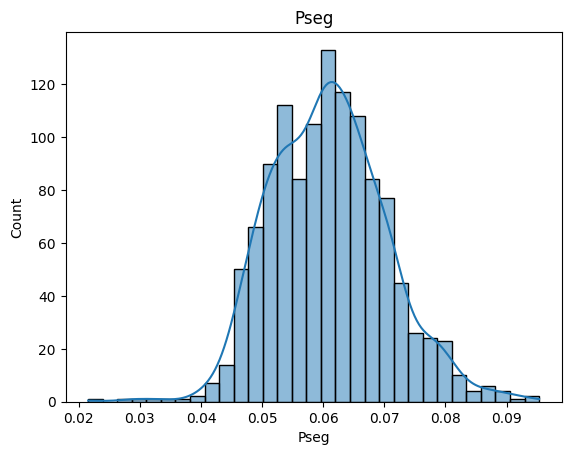

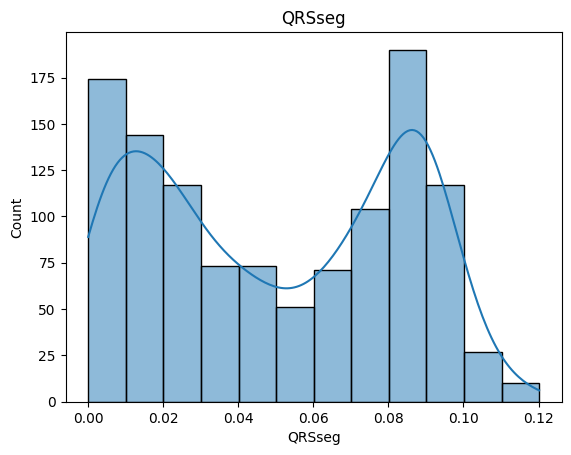

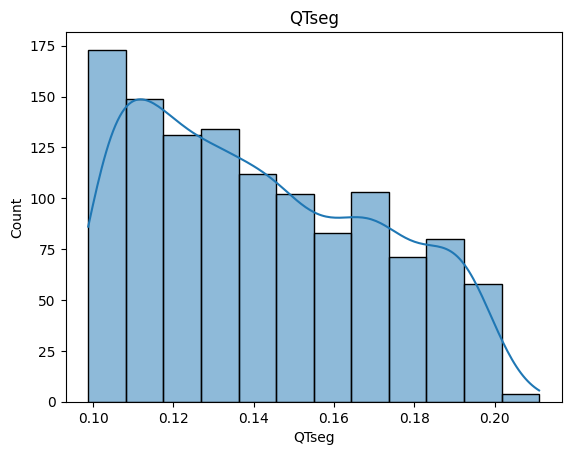

In [ ]:
segments = ['Pseg', 'QRSseg', 'QTseg']

for col in segments:
    sns.histplot(df[col], kde=True)
    plt.title(col)
    plt.show()

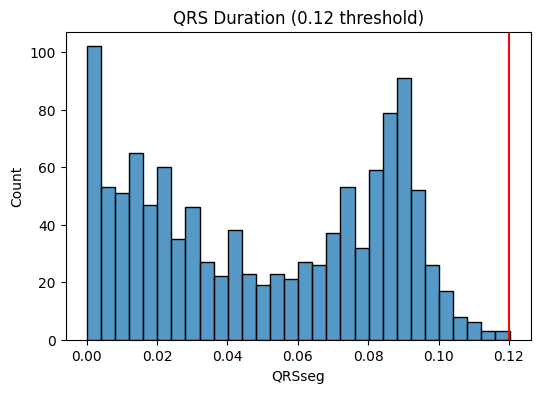

In [ ]:
plt.figure(figsize=(6,4))
sns.histplot(df['QRSseg'], bins=30)
plt.axvline(0.12, color='red')
plt.title("QRS Duration (0.12 threshold)")
plt.show()

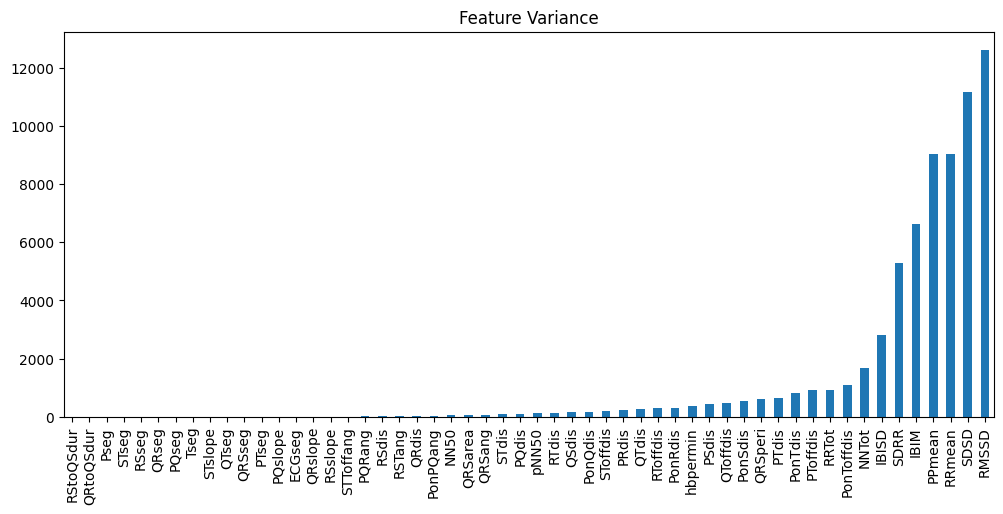

In [ ]:
variance = df[num_cols].var()

variance.sort_values().plot(kind='bar', figsize=(12,5))
plt.title("Feature Variance")
plt.show()

In [ ]:
print(type(df[col]), df[col].shape)
print(type(df[target]), df[target].shape)

<class 'pandas.core.series.Series'> (1200,)
<class 'pandas.core.series.Series'> (1200,)


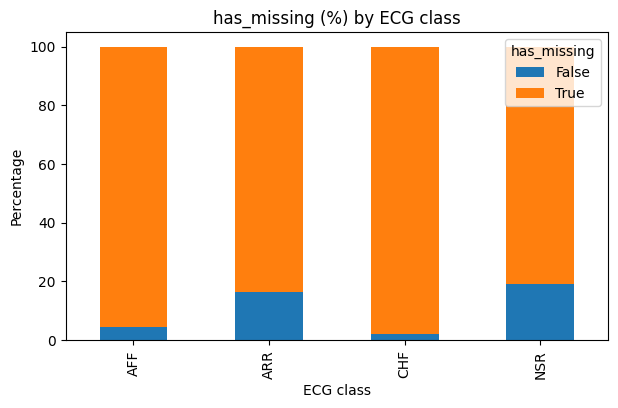

In [ ]:
indicator_cols = [col for col in df.columns if col.endswith('_missing')]

for col in indicator_cols[:5]:
    temp = pd.crosstab(df[col], df['ECG_signal'], normalize='columns') * 100

    temp.T.plot(kind='bar', stacked=True, figsize=(7,4))
    plt.title(f'{col} (%) by ECG class')
    plt.ylabel('Percentage')
    plt.xlabel('ECG class')
    plt.legend(title=col)
    plt.show()

<h3 style="color:#8F9F87; font-weight:700;">Correlation Analysis </h3>

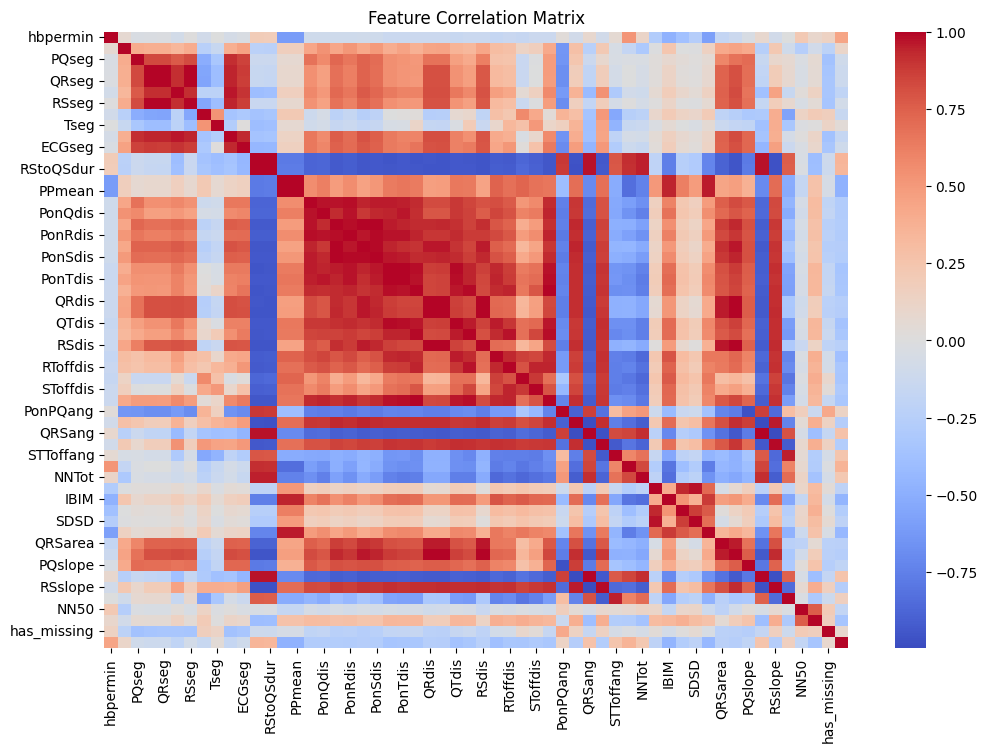

In [ ]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12,8))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title("Feature Correlation Matrix")
plt.show()

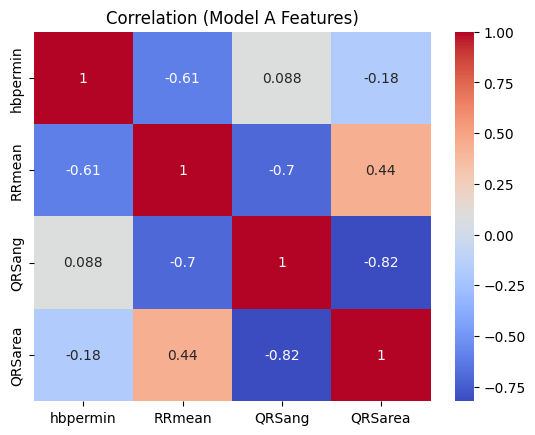

In [ ]:
selected = ['hbpermin', 'RRmean', 'QRSang', 'QRSarea']

sns.heatmap(df[selected].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation (Model A Features)")
plt.show()

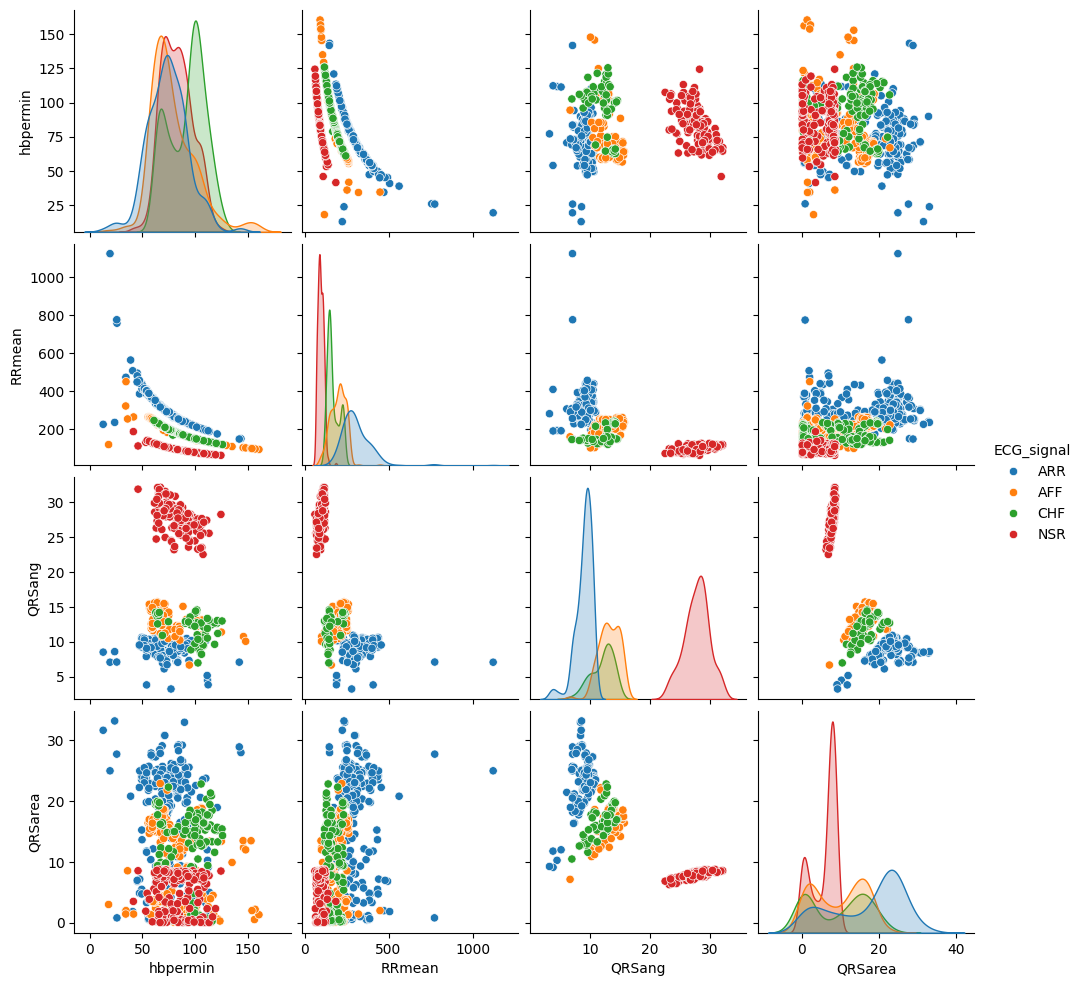

In [ ]:
sns.pairplot(df, vars=selected, hue='ECG_signal')
plt.show()

This correlation analysis reveals that there is no evidence of strong multicollinearity with the four selected features. Pairwise plots show that NSR clusters are quite tight and for the most part well separated. AFF and CHF overlap quite a lot. Hbpermin and RRmean also have nonlinear relationships.

<h3 style="color:#8F9F87; font-weight:700;">Modelling </h3>


In [ ]:
raw_features = ['hbpermin', 'RRmean', 'QRSang', 'QRSarea']

X_raw = df[raw_features].copy()
y = df['ECG_signal']


In [ ]:
#KNN Imputation on baseline features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

imputer = KNNImputer(n_neighbors=5, weights='distance')
X_imputed_scaled = imputer.fit_transform(X_scaled)

X_imputed = pd.DataFrame(
    scaler.inverse_transform(X_imputed_scaled),
    columns=raw_features
)

In [ ]:
#Transform features for model
X_model = pd.DataFrame()

X_model['hbpermin'] = X_imputed['hbpermin']
X_model['RRmean_log'] = np.log1p(X_imputed['RRmean'])
X_model['QRSarea'] = X_imputed['QRSarea']
X_model['QRSang_sin'] = np.sin(np.deg2rad(X_imputed['QRSang']))
X_model['QRSang_cos'] = np.cos(np.deg2rad(X_imputed['QRSang']))

model_features = [
    'hbpermin',
    'RRmean_log',
    'QRSarea',
    'QRSang_sin',
    'QRSang_cos'
]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_model[model_features],
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
rf = RandomForestClassifier(n_estimators=300, random_state=42)
et = ExtraTreesClassifier(n_estimators=300, random_state=42)
svm = SVC(probability=True, random_state=42)

ensemble = VotingClassifier(
    estimators=[
        ('rf', rf),
        ('et', et),
        ('svm', svm)
    ],
    voting='soft'
)

ensemble.fit(X_train, y_train)

VotingClassifier(estimators=[('rf',
                              RandomForestClassifier(n_estimators=300,
                                                     random_state=42)),
                             ('et',
                              ExtraTreesClassifier(n_estimators=300,
                                                   random_state=42)),
                             ('svm', SVC(probability=True, random_state=42))],
                 voting='soft')

<h3 style="color:#8F9F87; font-weight:700;">Model Evaluation</h3>


In [ ]:
y_pred = ensemble.predict(X_test)
y_prob = ensemble.predict_proba(X_test)

classes = ensemble.classes_

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         AFF       0.77      0.68      0.73        60
         ARR       1.00      0.97      0.98        60
         CHF       0.71      0.80      0.75        60
         NSR       0.98      1.00      0.99        60

    accuracy                           0.86       240
   macro avg       0.87      0.86      0.86       240
weighted avg       0.87      0.86      0.86       240



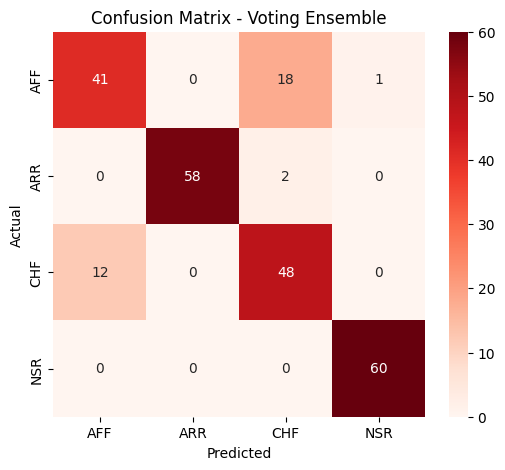

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=classes)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Reds',
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Voting Ensemble")
plt.show()

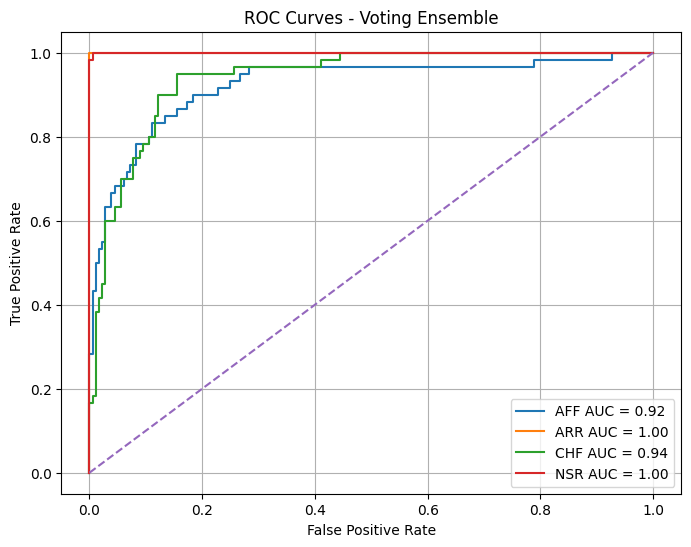

In [ ]:
y_test_bin = label_binarize(y_test, classes=classes)

plt.figure(figsize=(8,6))

for i, class_name in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'{class_name} AUC = {roc_auc:.2f}')

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Voting Ensemble")
plt.legend()
plt.grid(True)
plt.show()

      Feature  Importance
4  QRSang_cos    0.262680
3  QRSang_sin    0.258817
1  RRmean_log    0.254583
2     QRSarea    0.123553
0    hbpermin    0.100366


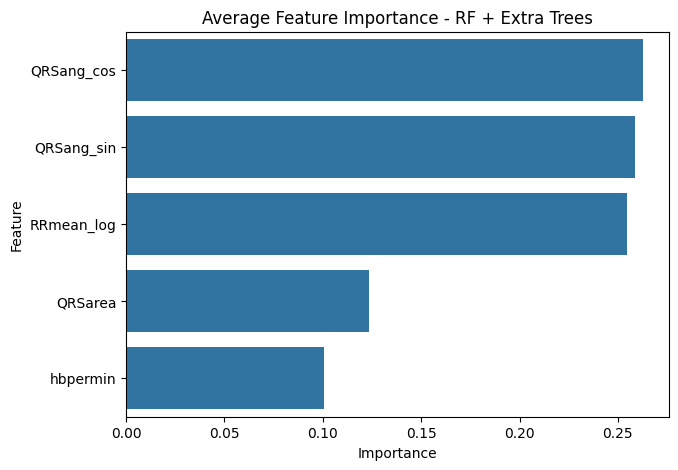

In [ ]:
rf_model = ensemble.named_estimators_['rf']
et_model = ensemble.named_estimators_['et']

rf_importance = rf_model.feature_importances_
et_importance = et_model.feature_importances_

avg_importance = (rf_importance + et_importance) / 2

importance_df = pd.DataFrame({
    'Feature': model_features,
    'Importance': avg_importance
}).sort_values(by='Importance', ascending=False)

print(importance_df)

plt.figure(figsize=(7,5))
sns.barplot(data=importance_df, x='Importance', y='Feature')
plt.title("Average Feature Importance - RF + Extra Trees")
plt.show()

<h3 style="color:#8F9F87; font-weight:700;">Prediction function for new demo cases</h3>


In [ ]:
def predict_ecg_case(hbpermin=np.nan, RRmean=np.nan, QRSang=np.nan, QRSarea=np.nan):
    demo_case = pd.DataFrame([{
        'hbpermin': hbpermin,
        'RRmean': RRmean,
        'QRSang': QRSang,
        'QRSarea': QRSarea
    }])

    combined = pd.concat([X_raw, demo_case], ignore_index=True)

    combined_scaled = scaler.transform(combined)
    combined_imputed_scaled = imputer.transform(combined_scaled)

    combined_imputed = pd.DataFrame(
        scaler.inverse_transform(combined_imputed_scaled),
        columns=raw_features
    )

    demo_imputed = combined_imputed.iloc[[-1]]

    demo_model = pd.DataFrame()

    demo_model['hbpermin'] = demo_imputed['hbpermin']
    demo_model['RRmean_log'] = np.log1p(demo_imputed['RRmean'])
    demo_model['QRSarea'] = demo_imputed['QRSarea']
    demo_model['QRSang_sin'] = np.sin(np.deg2rad(demo_imputed['QRSang']))
    demo_model['QRSang_cos'] = np.cos(np.deg2rad(demo_imputed['QRSang']))

    demo_model = demo_model[model_features]

    prediction = ensemble.predict(demo_model)
    probabilities = pd.DataFrame(
        ensemble.predict_proba(demo_model),
        columns=ensemble.classes_
    )

    print("Original input:")
    print(demo_case)

    print("\nAfter KNN imputation:")
    print(demo_imputed)

    print("\nModel input after transformations:")
    print(demo_model)

    print("\nClass probabilities:")
    print(probabilities)

    print(f"\n\nPredicted ECG class: {prediction[0]}\n\n")

    return prediction[0], probabilities, demo_imputed, demo_model


In [ ]:
def plot_prediction_probs(probs_df):
    # Convert first row to Series
    probs = probs_df.iloc[0]
    probs = probs.sort_values(ascending=False)
    plt.figure(figsize=(6,4))
    sns.barplot(
        x=probs.index,
        y=probs.values
    )

    plt.ylim(0, 1)
    plt.ylabel("Probability")
    plt.xlabel("ECG Class")
    plt.title("Prediction Probabilities for Demo Case")

    # Annotate values
    for i, v in enumerate(probs.values):
        plt.text(i, v + 0.02, f"{v:.2f}", ha='center')

    plt.show()

<h3 style="color:#8F9F87; font-weight:700;">Prediction demo</h3>

Original input:
   hbpermin  RRmean  QRSang  QRSarea
0        70     108    30.2      7.9

After KNN imputation:
      hbpermin  RRmean  QRSang  QRSarea
1200      70.0   108.0    30.2      7.9

Model input after transformations:
      hbpermin  RRmean_log  QRSarea  QRSang_sin  QRSang_cos
1200      70.0    4.691348      7.9     0.50302    0.864275

Class probabilities:
        AFF       ARR       CHF      NSR
0  0.117489  0.052118  0.052363  0.77803


Predicted ECG class: NSR




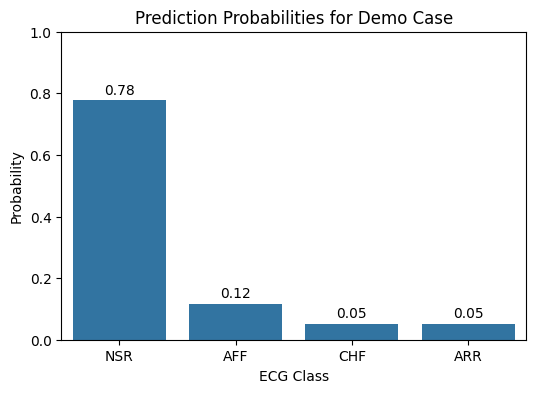

In [ ]:
pred, probs, _, _ = predict_ecg_case(
    hbpermin=101,
    RRmean=150,
    QRSang=12.8,
    QRSarea=1
)

plot_prediction_probs(probs)